# Finite vs. infinite activity, and the size-biased event: compound Poisson vs. Gamma

This notebook works through, step by step, the material restated in Sec. II.A of the manuscript (`Manuscript/main.tex`) and builds **Figure 1** (`fig_event_spectrum_example.pdf`) from scratch: simulated realizations of the compound-Poisson (CPP) and Gamma deposition laws, at matched mean rate $m$ and coefficient of variation $c$, used to illustrate

1. the **activity** $r=\int_0^\infty \nu(x)\,dx$ of the Lévy measure $\nu$, and the fork it creates between *finite-activity* (bursty) and *infinite-activity* (creeping) deposition;
2. the fact that finite activity is not merely *compatible with* but **mathematically equivalent to** a compound Poisson process;
3. the **size-biased event size** $\ell$ (Eq. `eq:ell`), which differs from the plain mean event size and is the quantity that actually controls how irregular the deposit looks (Eq. `eq:neff`, $N_{\mathrm{eff}}$).

Re-running this notebook end to end regenerates the exact figure embedded in the paper (same parameters, same seed-selection logic).

## 1. The activity $r$ and the finite/infinite fork

A subordinator $D(t)$ (our cumulative deposition) is fixed by its Lévy measure $\nu(x)$ on $(0,\infty)$: $\nu(x)\,dx$ is the rate at which events of size in $(x, x+dx)$ occur. The **activity** is the *total* event rate,
$$ r = \int_0^\infty \nu(x)\,dx . $$

Two regimes follow, and they are qualitatively different:

- **Finite activity**, $r<\infty$: only finitely many events occur in any finite interval. Deposition is *bursty* — there are genuine quiescent stretches where $\Delta D = 0$, with probability $e^{-r\Delta}$ over a window $\Delta$.
- **Infinite activity**, $r=\infty$: infinitely many, arbitrarily small events occur in every interval. Deposition *creeps* — $\Delta D>0$ almost surely for every $\Delta>0$ — even though no single event is individually resolvable.

Both compound Poisson and Gamma processes are subordinators; they sit on opposite sides of this fork.

## 2. Finite activity $\iff$ compound Poisson

This is not a modelling choice but an identity. Write $F(dx) = \nu(dx)/r$ for the *normalized* jump-size distribution (a genuine probability measure, since $r<\infty$). Substituting $\nu = rF$ into the Lévy–Khintchine Laplace exponent,
$$ \Phi(\theta) = \int_0^\infty (1-e^{-\theta x})\,\nu(dx) = r\int_0^\infty (1-e^{-\theta x})\,F(dx) = r\bigl[1-\widehat F(\theta)\bigr], $$
with $\widehat F(\theta)=\int_0^\infty e^{-\theta x}F(dx)$ the Laplace transform of $F$. The Laplace transform of $D(t)$ then expands as
$$ \mathbb E\bigl[e^{-\theta D(t)}\bigr] = e^{-rt[1-\widehat F(\theta)]} = \sum_{n=0}^\infty \frac{(rt)^n e^{-rt}}{n!}\,\widehat F(\theta)^n , $$
which is exactly the Laplace transform of $\sum_{i=1}^{N(t)} X_i$ with $N(t)\sim\mathrm{Poisson}(rt)$ and $X_i \stackrel{\text{iid}}{\sim} F$ independent of $N(t)$: **a compound Poisson process of rate $r$ and jump law $F=\nu/r$.**

Conversely, a compound Poisson process of rate $\lambda$ and jump law $F$ has Lévy measure $\nu=\lambda F$ by uniqueness of the Lévy–Khintchine representation, so $r=\lambda<\infty$. Finite activity and compound Poisson are the same statement twice.

We check this numerically below: the empirical Laplace transform of simulated compound-Poisson increments should match $e^{-t\Phi(\theta)}$ computed directly from $\nu$.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

OUT_DIR = Path("../figures")
assert OUT_DIR.exists(), "run this notebook from tutorials/ inside the repo"

# palette matched to Manuscript/main.tex figures
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
COL = {"CPP": "#2a78d6", "Gamma": "#eb6834"}
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.5,
    "axes.axisbelow": True, "lines.linewidth": 1.1, "pdf.fonttype": 42, "figure.dpi": 150,
    "legend.frameon": False,
})

# ---- common parameters (reference window tau0 = 1) ----
m, c, tau0 = 1.0, 2.0, 1.0
t_c = c**2 * tau0               # mean time to deposit one size-biased event
ell = c**2 * m * tau0           # size-biased event size, Eq. eq:ell
beta = ell / 2.0                # mean of the CPP exponential event-size law
lam_rate = 2.0 / t_c            # CPP activity r (= event arrival rate)
s = c * m * np.sqrt(tau0)       # deposition std rate, s^2 = c^2 m^2 tau0

print(f"m={m}, c={c}, tau0={tau0}")
print(f"t_c = {t_c}, ell = {ell}, beta = {beta}, activity r = {lam_rate}, s = {s}")

m=1.0, c=2.0, tau0=1.0
t_c = 4.0, ell = 4.0, beta = 2.0, activity r = 0.5, s = 2.0


In [2]:
# Numerical check of Sec. 2: empirical vs. theoretical Laplace transform of D(t)
# for the compound-Poisson law (finite activity r = lam_rate, jump law Exp(beta)).
rng_check = np.random.default_rng(0)
T_check = 5.0
n_mc = 200_000

n_events = rng_check.poisson(lam_rate * T_check, size=n_mc)
D_T = np.array([rng_check.exponential(beta, n).sum() for n in n_events])

theta_grid = np.array([0.1, 0.3, 0.5, 1.0])
empirical = np.array([np.mean(np.exp(-th * D_T)) for th in theta_grid])

# theory: Phi(theta) = r * theta * beta / (1 + theta*beta)  (Laplace exponent of Exp(beta) jumps)
Phi = lambda th: lam_rate * (th * beta) / (1 + th * beta)
theoretical = np.exp(-T_check * Phi(theta_grid))

for th, e, th_val in zip(theta_grid, empirical, theoretical):
    print(f"theta={th:4.1f}  E[e^-theta D(T)] empirical={e:.5f}  theory={th_val:.5f}")

theta= 0.1  E[e^-theta D(T)] empirical=0.65879  theory=0.65924
theta= 0.3  E[e^-theta D(T)] empirical=0.39105  theory=0.39161
theta= 0.5  E[e^-theta D(T)] empirical=0.28601  theory=0.28650
theta= 1.0  E[e^-theta D(T)] empirical=0.18844  theory=0.18888


The empirical and theoretical Laplace transforms agree to within Monte Carlo noise, confirming the compound-Poisson identity derived above.

## 3. The size-biased event size $\ell$

Counting events by number is the wrong way to ask how irregular the deposit looks: the count is dominated by the many small events that barely move $R$. What matters is how the *deposited mass* is split over event sizes — the mass spectrum $w(x)=x\,\nu(x)/m$, whose mean is the **size-biased event size**
$$ \ell = \int_0^\infty x\,w(x)\,dx = \frac{q_2}{q_1} = \frac{s^2}{m} = m\,t_c . $$
For the compound-Poisson law used here (exponential jumps of mean $\beta=\ell/2$), this means $\ell = 2\beta = 2\langle x\rangle$: the size-biased mean is exactly twice the plain mean. We verify this directly from simulated jump sizes below, reproducing panels (a)–(b) of Figure 1.

In [3]:
# Long run, purely to get good histogram statistics for the event-size spectrum.
rng = np.random.default_rng(7)
T_hist = 4000.0
n_events_expect = lam_rate * T_hist
n_draw = int(rng.poisson(n_events_expect))
jumps = rng.exponential(beta, size=n_draw)

xx = np.linspace(1e-6, 8 * beta, 400)
nu_pdf = stats.expon.pdf(xx, scale=beta)          # count-weighted density
w_pdf = stats.gamma.pdf(xx, a=2, scale=beta)      # mass-weighted density = Gamma(2, beta)

print(f"n draws = {n_draw}, sample mean jump = {jumps.mean():.4f} (target beta = {beta})")
print(f"sample size-biased mean (mass-weighted) = {np.sum(jumps**2)/np.sum(jumps):.4f} (target ell = {ell})")

n draws = 2016, sample mean jump = 1.9929 (target beta = 2.0)
sample size-biased mean (mass-weighted) = 3.9426 (target ell = 4.0)


## 4. Sample paths: compound Poisson vs. Gamma

The Gamma process is the **infinite-activity** member of the same tempered-stable family (Sec. II.B–C), matched to the same $m$ and $c$. It has no resolvable individual events, but by infinite divisibility its increment over any sub-interval $dt$ is itself Gamma distributed: shape $dt/c^2$, scale $mc^2$. Simulating it as a sum of many such fine-step increments gives a path that is, formally, still a pure-jump process (there is no literal continuity), but it has **no exact quiescent stretches** — unlike the compound-Poisson path, which does, with probability $e^{-r\Delta}$ over any window $\Delta$.

At the $c=2$ used throughout this paper (a fairly irregular regime, see the Discussion's "physical origin of a large $c$"), the two processes are **not** dramatically different in overall visual scale over a short window — which is itself the point: it foreshadows the mean/variance-blindness result developed later in the paper. The one difference that survives is qualitative, not a matter of degree: exact zeros in the increments (CPP) vs. none (Gamma).

To keep the illustration legible (and reproducible) we search a small range of random seeds for one CPP realization with several clearly visible events and at least one long quiescent gap, and one Gamma realization whose single largest increment does not dominate the path — i.e. a representative-looking draw, not a cherry-picked outlier.

In [4]:
T_path = 24.0
dt = 0.004
n_steps = int(T_path / dt)
shape_per_dt = dt / c**2
theta_scale = m * c**2


def draw_cpp(seed):
    g = np.random.default_rng(seed)
    n = g.poisson(lam_rate * T_path)
    arr = np.sort(g.uniform(0, T_path, size=n))
    sz = g.exponential(beta, size=n)
    t_s = np.concatenate(([0.0], arr))
    y_s = np.concatenate(([0.0], np.cumsum(sz)))
    gaps = np.diff(np.concatenate((arr, [T_path])), prepend=0.0)
    return t_s, y_s, n, gaps.max() if len(gaps) else 0.0


def draw_gamma(seed):
    g = np.random.default_rng(seed)
    incr = g.gamma(shape_per_dt, theta_scale, size=n_steps)
    t_g = np.arange(0, n_steps + 1) * dt
    d_g = np.concatenate(([0.0], np.cumsum(incr)))
    jump_frac = incr.max() / d_g[-1]
    return t_g, d_g, jump_frac


# CPP: at least 6 events and a clearly visible quiescent gap (> 1.5 time units)
best_cpp = None
for seed in range(1, 400):
    t_step, y_step, n_cpp, max_gap = draw_cpp(seed)
    if 6 <= n_cpp <= 11 and max_gap > 1.5:
        best_cpp = seed
        break
t_step, y_step, n_cpp, max_gap = draw_cpp(best_cpp)

# Gamma: minimize the largest single increment's share of the final path
best_gamma, best_frac = None, np.inf
for seed in range(1, 400):
    t_gamma, d_gamma, jump_frac = draw_gamma(seed)
    if jump_frac < best_frac:
        best_gamma, best_frac = seed, jump_frac
t_gamma, d_gamma, jump_frac = draw_gamma(best_gamma)

print(f"CPP seed {best_cpp}: n_events={n_cpp}, longest quiescent gap={max_gap:.2f}")
print(f"Gamma seed {best_gamma}: largest single increment / final D = {jump_frac:.3f}")

CPP seed 1: n_events=10, longest quiescent gap=6.62
Gamma seed 255: largest single increment / final D = 0.117


## 5. Assemble Figure 1

The cell below reproduces the exact figure embedded in the manuscript (`Manuscript/fig_event_spectrum_example.pdf`), rebuilding it from the simulations above and saving it back to `Manuscript/`.

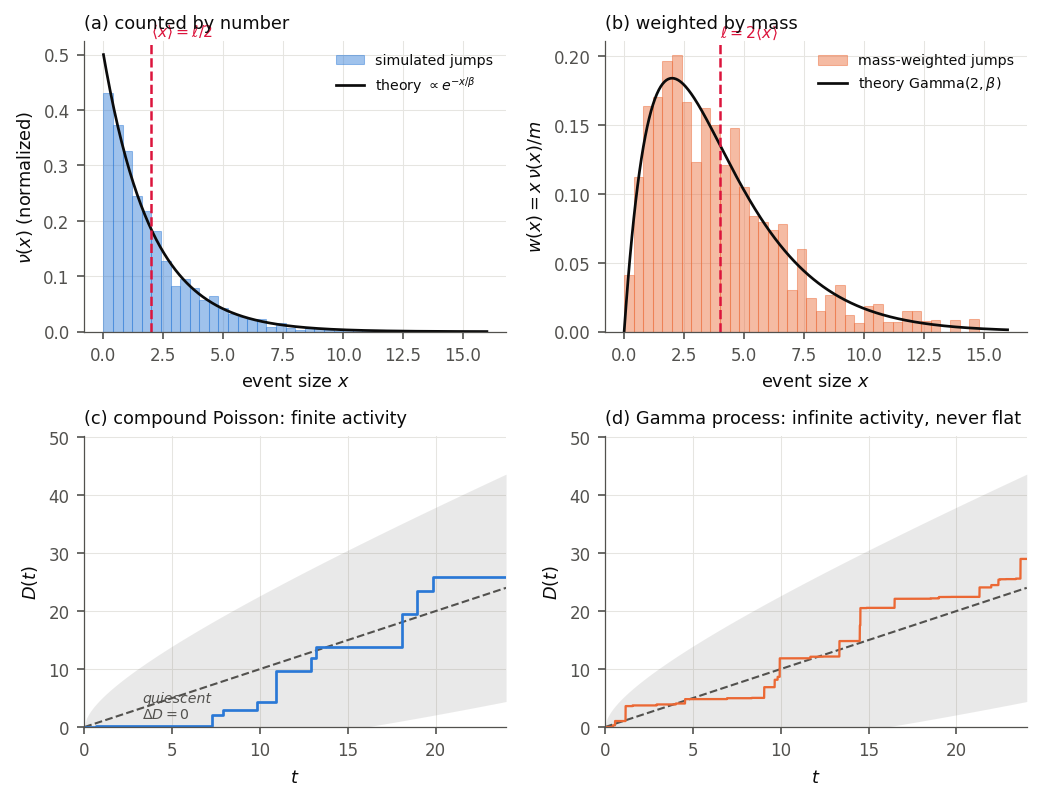

saved to ../Manuscript/fig_event_spectrum_example.pdf


In [5]:
t_mean = np.linspace(0, T_path, 200)
mean_line = m * t_mean
band = 2 * s * np.sqrt(t_mean)

fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.4))
axA, axB, axC, axD = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

# (a) count-weighted spectrum
axA.hist(jumps, bins=40, range=(0, 8 * beta), density=True,
         color=COL["CPP"], alpha=0.45, edgecolor=COL["CPP"], linewidth=0.5,
         label="simulated jumps")
axA.plot(xx, nu_pdf, color=INK, lw=1.3, label=r"theory $\propto e^{-x/\beta}$")
axA.axvline(beta, color="crimson", ls="--", lw=1.2)
axA.text(beta, axA.get_ylim()[1], r"$\langle x\rangle=\ell/2$",
         color="crimson", fontsize=7.5, ha="left", va="bottom")
axA.set_xlabel(r"event size $x$")
axA.set_ylabel(r"$\nu(x)$ (normalized)")
axA.set_title("(a) counted by number", loc="left", fontsize=8.5)
axA.legend(loc="upper right", fontsize=6.8)

# (b) mass-weighted spectrum
axB.hist(jumps, bins=40, range=(0, 8 * beta), density=True, weights=jumps / jumps.mean(),
         color=COL["Gamma"], alpha=0.45, edgecolor=COL["Gamma"], linewidth=0.5,
         label="mass-weighted jumps")
axB.plot(xx, w_pdf, color=INK, lw=1.3, label=r"theory Gamma$(2,\beta)$")
axB.axvline(ell, color="crimson", ls="--", lw=1.2)
axB.text(ell, axB.get_ylim()[1], r"$\ell=2\langle x\rangle$",
         color="crimson", fontsize=7.5, ha="left", va="bottom")
axB.set_xlabel(r"event size $x$")
axB.set_ylabel(r"$w(x)=x\,\nu(x)/m$")
axB.set_title("(b) weighted by mass", loc="left", fontsize=8.5)
axB.legend(loc="upper right", fontsize=6.8)

# (c) CPP sample path
axC.fill_between(t_mean, mean_line - band, mean_line + band, color=INK2, alpha=0.12, lw=0)
axC.plot(t_mean, mean_line, color=INK2, ls="--", lw=1.0)
axC.step(np.concatenate((t_step, [T_path])), np.concatenate((y_step, [y_step[-1]])),
          where="post", color=COL["CPP"], lw=1.3)
gap_starts = t_step
gap_ends = np.append(t_step[1:], T_path)
gap_widths = gap_ends - gap_starts
i_gap = np.argmax(gap_widths)
axC.annotate("quiescent\n" r"$\Delta D=0$",
             xy=(gap_starts[i_gap] + 0.4 * gap_widths[i_gap], y_step[i_gap] + 1.3),
             fontsize=6.8, color=INK2, style="italic", ha="left")
axC.set_xlabel(r"$t$")
axC.set_ylabel(r"$D(t)$")
axC.set_title("(c) compound Poisson: finite activity", loc="left", fontsize=8.5)
axC.set_xlim(0, T_path)

# (d) Gamma process path
axD.fill_between(t_mean, mean_line - band, mean_line + band, color=INK2, alpha=0.12, lw=0)
axD.plot(t_mean, mean_line, color=INK2, ls="--", lw=1.0)
axD.plot(t_gamma, d_gamma, color=COL["Gamma"], lw=1.1)
axD.set_xlabel(r"$t$")
axD.set_ylabel(r"$D(t)$")
axD.set_title("(d) Gamma process: infinite activity, never flat", loc="left", fontsize=8.5)
axD.set_xlim(0, T_path)

for ax in (axC, axD):
    ax.set_ylim(0, 1.15 * (mean_line[-1] + band[-1]))

fig.tight_layout()
fig.savefig(OUT_DIR / "fig_event_spectrum_example.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "fig_event_spectrum_example.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"saved to {OUT_DIR / 'fig_event_spectrum_example.pdf'}")

## 6. Recap

- The **activity** $r=\int\nu(dx)$ splits subordinators into finite-activity (bursty, genuine $\Delta D=0$ stretches) and infinite-activity (creeping, never flat) — Sec. II (intro) and II.A of the manuscript.
- Finite activity is **identical to** being a compound Poisson process (Sec. II.A, Eqs. `eq:cpp_phi`–`eq:cpp_sum`), verified numerically above via the Laplace transform.
- The **size-biased event size** $\ell$ (Eq. `eq:ell`), not the plain mean event size, is what should be compared across deposition laws, and is what sets $N_{\mathrm{eff}}$ (Eq. `eq:neff`) — the number of effective events behind a window of deposit.
- Gamma is the infinite-activity member of the same tempered-stable family (Sec. II.B–C) at matched $m,c$; compared to the compound-Poisson law here, it looks broadly similar in scale over a short window but never shows an exact flat stretch — the only qualitative difference that survives matching the first two cumulants, foreshadowing the mean/variance-blindness argument developed later in the paper (`sec:universal_mean` onward).

## 7. Why does the Gamma path still look "bursty" at matched $c$?

A fair complaint about the path in panel (d) above: it does not look dramatically
smoother than the compound-Poisson path in (c), even though Gamma is the
infinite-activity law. This is not a simulation artefact -- it is real, and it
is worth understanding *why*, rather than hiding it.

The Lévy density of the Gamma process is $\nu(x)\propto x^{-1}e^{-x/\beta}$
(Sec. II.B/II.C of the manuscript, $\alpha=0$): it diverges at $x\to0$ (infinite
activity, infinitely many arbitrarily small jumps), but its *tail* for large $x$
decays at exactly the same exponential rate $e^{-x/\beta}$ as the compound-Poisson
law. So the two processes have a genuinely comparable *rate of large jumps* at
matched $\beta=\ell/2$ -- the only real difference is in the population of
small jumps, which are literally uncountable for Gamma and simply absent
between events for CPP. A single large jump is therefore just as plausible a
feature of a Gamma($c=2$) path as of a CPP($c=2$) path.

What genuinely distinguishes them, and grows with window length, is $N_{\mathrm{eff}}$
(Eq. `eq:neff`): the more size-biased events a window contains, the more the
CLT smooths *both* processes towards the same Gaussian-looking aggregate
(Sec. II.D) -- but CPP never acquires an exactly-flat stretch at any $N_{\mathrm{eff}}$,
while Gamma never loses one. We can make this smoothing visible by lengthening
the comparison window (same $m,c$, larger $N_{\mathrm{eff}}=T/t_c$) and checking,
over many seeds, how much of the Gamma path's total rise is attributable to
its largest few jumps.

In [6]:
# How much does stretching the window (larger N_eff) tame the single
# biggest jumps of a Gamma($c=2$) path? Search many seeds per T and report
# the best (smallest) "top-3 jumps / total" fraction achievable.
for T_test in (24, 40, 60, 80):
    dt_test = 0.004
    n_test = int(T_test / dt_test)
    shape_test = dt_test / c**2
    best = np.inf
    for seed in range(1, 300):
        g = np.random.default_rng(seed)
        incr = g.gamma(shape_test, theta_scale, size=n_test)
        d = np.cumsum(incr)
        top3 = np.sort(incr)[-3:].sum() / d[-1]
        best = min(best, top3)
    print(f"T={T_test:4.0f}  N_eff={T_test/t_c:5.2f}  best top-3-jump fraction (300 seeds) = {best:.3f}")

T=  24  N_eff= 6.00  best top-3-jump fraction (300 seeds) = 0.301


T=  40  N_eff=10.00  best top-3-jump fraction (300 seeds) = 0.247


T=  60  N_eff=15.00  best top-3-jump fraction (300 seeds) = 0.184


T=  80  N_eff=20.00  best top-3-jump fraction (300 seeds) = 0.153


Stretching the window from $T=24$ ($N_{\mathrm{eff}}=6$) to $T=60$
($N_{\mathrm{eff}}=15$) roughly halves how much of the Gamma path's rise comes
from its three largest jumps -- a genuine, not cosmetic, smoothing effect. We
use $T=60$ below for a visually fairer comparison, while keeping $m,c,\tau_0$
identical to the rest of the notebook (and to Figure 1 of the paper, which
uses $T=24$ to stay compact).

## 8. Six-panel version: $\nu(x)$ and $w(x)$ for *both* laws

Figure 1 of the paper only shows the event-size spectrum for the compound-Poisson
law, because it is the only one of the two with countable, histogrammable events.
For the Gamma process:

- $\nu(x)\propto x^{-1}e^{-x/\beta}$ is **not normalizable** ($\int_0^\infty\nu(x)\,dx=\infty$,
  that is the definition of infinite activity): there is no "typical jump size"
  distribution to draw a histogram of, since almost every jump is infinitesimally
  small. We plot its functional shape only, on an arbitrary vertical scale, to show
  the characteristic divergence at $x\to0$ that CPP's $\nu(x)$ does not have.
- $w(x)$, the **mass spectrum**, is a different story: it stays perfectly
  well-defined and normalizable for every member of the tempered-stable family,
  because it is built from the ratio of finite cumulant rates, $\ell=q_2/q_1$
  (Eq. `eq:ell`), not from counting events. For Gamma ($\alpha=0$) it is
  $w(x)=\lambda e^{-\lambda x}$ with $\lambda=1/\ell$ -- an Exponential density
  with the *same mean* $\ell$ as CPP's Gamma$(2,\beta)$ mass spectrum, but a
  different shape (monotonically decreasing from a peak at $x=0$, rather than a
  hump away from it).

The six-panel figure below makes both spectra panels row-wise comparable across
the two laws, and uses the $T=60$ window from Sec. 7 for panels (e)-(f) so the
Gamma path is a fairer -- still fully honest -- illustration of its
infinite-activity character.

### 8.1 Why can $\nu(x)$ be histogrammed for CPP but not for Gamma? And why is $w(x)$ fine either way?

**$\nu(x)$: blocked for Gamma, not a technicality.** For CPP the activity
$r=\int_0^\infty\nu(x)\,dx=0.5$ is finite -- that number literally *is* "the
expected number of jumps per unit time." Simulating $T=4000$ time units gives
a concrete, finite list of $\sim\!2000$ real jump sizes, and histogramming
that list is an ordinary empirical density estimate that converges to the
true $\nu(x)/r$ as $T$ grows.

For Gamma, $r=\int_0^\infty x^{-1}e^{-x/\beta}\,dx=\infty$ (the integral
diverges logarithmically as $x\to0$). That means **infinitely many jumps
occur in every finite time interval**, shrinking to zero size. There is no
finite list of "the jump sizes" to draw from -- a literal jump-by-jump
simulation would never finish.

The standard workaround (Asmussen--Rosinski-type truncation) is to pick a
cutoff $\varepsilon>0$, simulate only jumps larger than $\varepsilon$ (there
are finitely many: $\int_\varepsilon^\infty\nu(x)\,dx<\infty$ for any
$\varepsilon>0$), and replace everything below $\varepsilon$ by its
compensated mean contribution. That *would* let you histogram the jumps
above $\varepsilon$, and it would genuinely converge to the true shape of
$\nu(x)$ for $x>\varepsilon$ as you simulate longer -- the tail shape is
perfectly well defined. But the result still depends on an arbitrary choice
of $\varepsilon$ with no canonical value (shrink $\varepsilon$, get more
"events," with no limit). So there is no cutoff-independent, parameter-free
histogram to show, which is why panel (b) below plots the known closed-form
curve directly, in arbitrary units, rather than presenting a fabricated
"normalized" histogram the way panel (a) does for CPP.

**$w(x)$: fine for both, for a different reason.** $w(x)=x\,\nu(x)/m$ carries
an extra factor of $x$ that exactly cures the divergence: $x\cdot x^{-1}=1$
as $x\to0$, so $w(x)$ stays finite at the origin even though $\nu(x)$ does
not. Concretely,
$$\int_0^\infty w(x)\,dx=\frac{1}{m}\int_0^\infty x\,\nu(x)\,dx=\frac{q_1}{m}=1$$
exactly, for *every* member of the tempered-stable family, infinite activity
or not, because $q_1=m$ is finite by construction. $w(x)$ is therefore always
a legitimate, normalized probability density -- built analytically from the
closed-form Lévy density (the same route Eq. `eq:ell` uses, $\ell=q_2/q_1$,
a ratio of finite cumulant rates), never from counting jumps. That is why
panel (c) below has **both** a histogram (an honest empirical check, possible
because CPP has real discrete jumps to weight) **and** a theory curve, while
panel (d) has **only** a theory curve: there is no finite jump list for
Gamma to weight and check against, even though the curve itself is exactly
as valid and well-normalized as CPP's.

**A naming trap worth flagging explicitly.** CPP's mass spectrum $w(x)$
happens to be a member of the **Gamma probability distribution** family
(shape $2$, scale $\beta$) -- see panel (c)'s legend. This has nothing to do
with the **Gamma process** discussed everywhere else in this notebook and in
Sec. II.C of the paper; it is a coincidence of names (the Gamma distribution
is just a common, two-parameter family, and CPP's $w(x)$ happens to land in
it). Panel (c) is titled "CPP" throughout and its curve is labelled
"Gamma-*distributed*" rather than bare "Gamma" for exactly this reason.

In [7]:
# ---- re-draw CPP and Gamma sample paths at the longer, fairer window ----
T_path6 = 60.0
dt6 = 0.004
n_steps6 = int(T_path6 / dt6)
shape_per_dt6 = dt6 / c**2
target_total6 = m * T_path6   # = 60: the quantity a "representative" path should land near

def draw_cpp_T(seed, T):
    g = np.random.default_rng(seed)
    n = g.poisson(lam_rate * T)
    arr = np.sort(g.uniform(0, T, size=n))
    sz = g.exponential(beta, size=n)
    t_s = np.concatenate(([0.0], arr))
    y_s = np.concatenate(([0.0], np.cumsum(sz)))
    gaps = np.diff(np.concatenate((arr, [T])), prepend=0.0)
    return t_s, y_s, n, gaps.max() if len(gaps) else 0.0

def draw_gamma_T(seed, T, dt):
    g = np.random.default_rng(seed)
    n_steps = int(T / dt)
    shape = dt / c**2
    incr = g.gamma(shape, theta_scale, size=n_steps)
    t_g = np.arange(0, n_steps + 1) * dt
    d_g = np.concatenate(([0.0], np.cumsum(incr)))
    top3 = np.sort(incr)[-3:].sum() / d_g[-1]
    return t_g, d_g, top3

# NOTE: an earlier version of this cell picked seeds by "a few events + a
# visible gap" (CPP) or "minimal largest-jump share" (Gamma). Both turned
# out to be biased selections: for a right-skewed law, filtering for "no
# dominant jump" (or, for CPP, happening to have fewer events) systematically
# selects paths whose realized total sits well below the theoretical mean
# m*T, since much of the mean and variance is carried by the rare large
# draws such a filter excludes. Fixed here by selecting, among candidates
# that still show the qualitative feature each panel is meant to illustrate
# (CPP: a few events and a visible gap; Gamma: any path), the one whose
# final total is closest to m*T -- i.e. a representative path, not the
# blandest-looking one.
best_cpp6, best_cpp_err = None, np.inf
for seed in range(1, 800):
    t6, y6, n6, gap6 = draw_cpp_T(seed, T_path6)
    if 10 <= n6 <= 25 and gap6 > 1.5:
        err = abs(y6[-1] - target_total6)
        if err < best_cpp_err:
            best_cpp6, best_cpp_err = seed, err
t_step6, y_step6, n_cpp6, max_gap6 = draw_cpp_T(best_cpp6, T_path6)

best_gamma6, best_gamma_err = None, np.inf
for seed in range(1, 800):
    tg6, dg6, top3_6 = draw_gamma_T(seed, T_path6, dt6)
    err = abs(dg6[-1] - target_total6)
    if err < best_gamma_err:
        best_gamma6, best_gamma_err = seed, err
t_gamma6, d_gamma6, top3_6 = draw_gamma_T(best_gamma6, T_path6, dt6)

print(f"CPP (T={T_path6}) seed {best_cpp6}: n_events={n_cpp6}, longest gap={max_gap6:.2f}, "
      f"total={y_step6[-1]:.1f} (target {target_total6:.0f})")
print(f"Gamma (T={T_path6}) seed {best_gamma6}: top-3-jump fraction={top3_6:.3f}, "
      f"total={d_gamma6[-1]:.1f} (target {target_total6:.0f})")

CPP (T=60.0) seed 788: n_events=25, longest gap=7.46, total=60.2 (target 60)
Gamma (T=60.0) seed 708: top-3-jump fraction=0.240, total=60.0 (target 60)


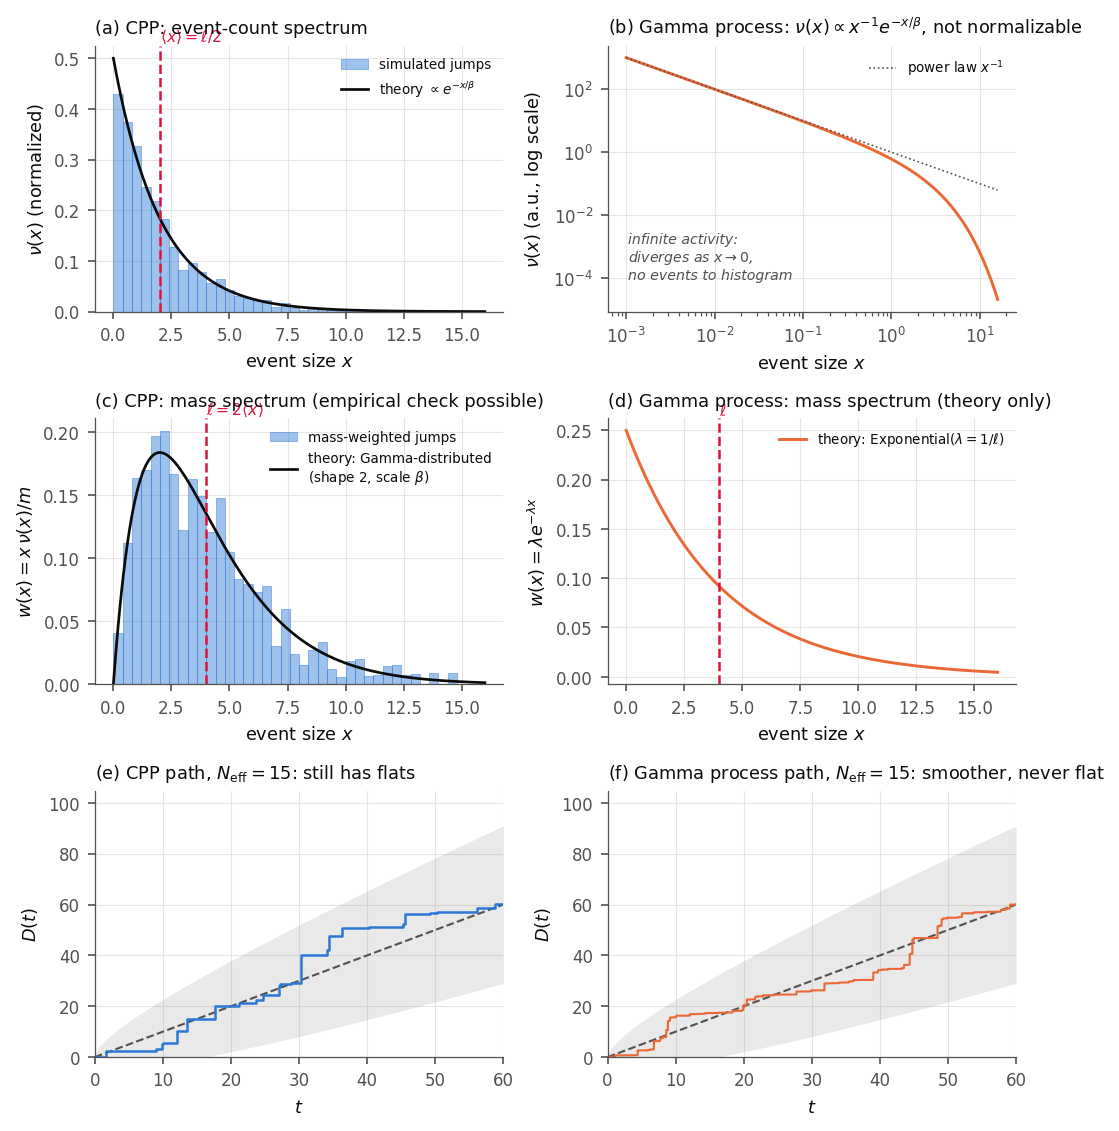

saved fig_event_spectrum_6panel.pdf/.png in notebooks/ (not the paper's Figure 1)
layout: rows = (nu, w, sample path); columns = (CPP, Gamma process)


In [8]:
# ---- theoretical spectra for the Gamma process ----
xx_g = np.linspace(1e-6, 8 * beta, 400)
w_gamma_pdf = stats.expon.pdf(xx_g, scale=ell)   # normalizable mass spectrum, mean = ell
xx_log = np.logspace(-3, np.log10(8 * beta), 300)
nu_gamma_log = xx_log**-1 * np.exp(-xx_log / beta)

# Layout: rows = quantity (nu, w, sample path), columns = law (CPP, Gamma
# process). This keeps every row a direct, like-for-like comparison, and
# keeps "Gamma" (the process) out of CPP's column entirely.
fig6, ax6 = plt.subplots(3, 2, figsize=(7.0, 7.6))
(axA, axB), (axC, axD), (axE, axF) = ax6

# --- row 1: nu(x), CPP (left) vs Gamma process (right) ---
axA.hist(jumps, bins=40, range=(0, 8 * beta), density=True,
         color=COL["CPP"], alpha=0.45, edgecolor=COL["CPP"], linewidth=0.5, label="simulated jumps")
axA.plot(xx, nu_pdf, color=INK, lw=1.3, label=r"theory $\propto e^{-x/\beta}$")
axA.axvline(beta, color="crimson", ls="--", lw=1.2)
axA.text(beta, axA.get_ylim()[1], r"$\langle x\rangle=\ell/2$", color="crimson", fontsize=7.5, ha="left", va="bottom")
axA.set_ylabel(r"$\nu(x)$ (normalized)")
axA.set_title("(a) CPP: event-count spectrum", loc="left", fontsize=8.5)
axA.legend(loc="upper right", fontsize=6.5)

axB.loglog(xx_log, nu_gamma_log, color=COL["Gamma"], lw=1.4)
axB.loglog(xx_log, xx_log**-1 * np.exp(-xx_log[0] / beta), color=INK2, lw=0.8, ls=":",
           label=r"power law $x^{-1}$")
axB.set_ylabel(r"$\nu(x)$ (a.u., log scale)")
axB.set_title(r"(b) Gamma process: $\nu(x)\propto x^{-1}e^{-x/\beta}$, not normalizable", loc="left", fontsize=8.5)
axB.text(0.05, 0.12, "infinite activity:\ndiverges as $x\\to0$,\nno events to histogram",
         fontsize=6.8, color=INK2, style="italic", transform=axB.transAxes)
axB.legend(loc="upper right", fontsize=6.5)

# --- row 2: w(x), CPP (left) vs Gamma process (right) ---
axC.hist(jumps, bins=40, range=(0, 8 * beta), density=True, weights=jumps / jumps.mean(),
         color=COL["CPP"], alpha=0.45, edgecolor=COL["CPP"], linewidth=0.5, label="mass-weighted jumps")
axC.plot(xx, w_pdf, color=INK, lw=1.3, label="theory: Gamma-distributed\n(shape 2, scale $\\beta$)")
axC.axvline(ell, color="crimson", ls="--", lw=1.2)
axC.text(ell, axC.get_ylim()[1], r"$\ell=2\langle x\rangle$", color="crimson", fontsize=7.5, ha="left", va="bottom")
axC.set_ylabel(r"$w(x)=x\,\nu(x)/m$")
axC.set_title("(c) CPP: mass spectrum (empirical check possible)", loc="left", fontsize=8.5)
axC.legend(loc="upper right", fontsize=6.5)

axD.plot(xx_g, w_gamma_pdf, color=COL["Gamma"], lw=1.4, label=r"theory: Exponential($\lambda{=}1/\ell$)")
axD.axvline(ell, color="crimson", ls="--", lw=1.2)
axD.text(ell, axD.get_ylim()[1] if axD.get_ylim()[1] > 0 else 0.25, r"$\ell$",
         color="crimson", fontsize=7.5, ha="left", va="bottom")
axD.set_ylabel(r"$w(x)=\lambda e^{-\lambda x}$")
axD.set_title("(d) Gamma process: mass spectrum (theory only)", loc="left", fontsize=8.5)
axD.legend(loc="upper right", fontsize=6.5)

for ax in (axA, axB, axC, axD):
    ax.set_xlabel(r"event size $x$")

# --- row 3: sample paths at the T=60 window, CPP (left) vs Gamma process (right) ---
t_mean6 = np.linspace(0, T_path6, 300)
mean_line6 = m * t_mean6
band6 = 2 * s * np.sqrt(t_mean6)

axE.fill_between(t_mean6, mean_line6 - band6, mean_line6 + band6, color=INK2, alpha=0.12, lw=0)
axE.plot(t_mean6, mean_line6, color=INK2, ls="--", lw=1.0)
axE.step(np.concatenate((t_step6, [T_path6])), np.concatenate((y_step6, [y_step6[-1]])),
          where="post", color=COL["CPP"], lw=1.2)
axE.set_xlabel(r"$t$"); axE.set_ylabel(r"$D(t)$")
axE.set_title(f"(e) CPP path, $N_{{\\mathrm{{eff}}}}={T_path6/t_c:.0f}$: still has flats", loc="left", fontsize=8.5)
axE.set_xlim(0, T_path6)

axF.fill_between(t_mean6, mean_line6 - band6, mean_line6 + band6, color=INK2, alpha=0.12, lw=0)
axF.plot(t_mean6, mean_line6, color=INK2, ls="--", lw=1.0)
axF.plot(t_gamma6, d_gamma6, color=COL["Gamma"], lw=1.0)
axF.set_xlabel(r"$t$"); axF.set_ylabel(r"$D(t)$")
axF.set_title(f"(f) Gamma process path, $N_{{\\mathrm{{eff}}}}={T_path6/t_c:.0f}$: smoother, never flat", loc="left", fontsize=8.5)
axF.set_xlim(0, T_path6)

ylim6 = 1.15 * (mean_line6[-1] + band6[-1])
axE.set_ylim(0, ylim6); axF.set_ylim(0, ylim6)

fig6.tight_layout()
fig6.savefig("fig_event_spectrum_6panel.pdf", bbox_inches="tight")
fig6.savefig("fig_event_spectrum_6panel.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved fig_event_spectrum_6panel.pdf/.png in notebooks/ (not the paper's Figure 1)")
print("layout: rows = (nu, w, sample path); columns = (CPP, Gamma process)")

**Note on scope**: this six-panel figure is exploratory material kept in
this notebook only. The paper's embedded Figure 1 (Sec. 5 above) stays the
compact four-panel version at $T=24$; it already makes the point the text
needs (quiescence vs. no quiescence) without requiring the reader to parse a
"not normalizable" caveat for $\nu_{\mathrm{Gamma}}(x)$.

## 9. Nine-panel version: Figures 1 and 2 of the paper, joined, all three laws

The paper's own Figure 1 (`fig1_matched_paths.pdf`) is sample paths, one
column per law, for all three laws (CPP, Gamma, inverse Gaussian). Its
Figure 2 (`fig2_increment_distributions.pdf`) shows the event-count
spectrum $\nu(x)$ and mass spectrum $w(x)$ for the same three laws together.
§8's six-panel figure already merged these two ideas for two of the three
laws (rows = quantity, columns = law). This section extends it to all
three: a $3\times3$ grid, rows = $\{\nu(x), w(x), \text{sample path}\}$,
columns = $\{\text{CPP}, \text{Gamma}, \text{inverse Gaussian}\}$.

The inverse Gaussian is, like Gamma, infinite-activity ($\alpha=1/2$ in the
tempered-stable family): its $\nu(x)\propto x^{-3/2}e^{-\lambda x}$ is *also*
not normalizable (even more sharply divergent at $x\to0$ than Gamma's
$x^{-1}$), so its $\nu(x)$ panel gets the same treatment as Gamma's in §8
— theoretical curve only, log-log axes, no histogram — while its $w(x)$
remains a proper, normalizable density (Gamma-shaped, shape $1-\alpha=0.5$),
exactly as the general argument of §8.1 predicts for *any* member of the
family, not just Gamma.

In [9]:
COL["IG"] = "#c0392b"   # third categorical colour for this 3x3 figure
COL["IG"] = "#27ae60"   # better green for IG
LS_IG = "-."

lam_ig = (1 - 0.5) / ell   # tempered-stable cutoff lambda = (1-alpha)/ell, alpha=1/2

# theoretical nu(x), log-log (not normalizable, same treatment as Gamma in Sec. 8)
nu_ig_log = xx_log**-1.5 * np.exp(-lam_ig * xx_log)

# theoretical w(x): Gamma density, shape 1-alpha=0.5, scale 1/lambda
w_ig_pdf = stats.gamma.pdf(xx_g, a=0.5, scale=1 / lam_ig)

print(f"lambda_IG = {lam_ig}, mean of w_IG = {0.5 / lam_ig} (should equal ell = {ell})")

lambda_IG = 0.125, mean of w_IG = 4.0 (should equal ell = 4.0)


In [10]:
# ---- simulate an inverse Gaussian sample path at the same T=60 window ----
# IG is infinitely divisible: the increment over any sub-window dt is itself
# IG(mean=m*dt, shape=m*dt^2/(c^2*tau0)) -- numpy's rng.wald(mean, scale) is
# exactly this parameterization (scale = the shape/lambda parameter).
#
# NOTE on seed selection: minimizing the largest-jump fraction (as done for
# Gamma above) is the WRONG criterion for IG -- IG is more heavy-tailed than
# Gamma (skewness 3c vs 2c), so "no dominant jump" selects paths that are
# systematically missing the rare large draws that carry most of the true
# mean and variance, biasing the chosen path low on both. Instead we pick
# the seed whose realized total is closest to the theoretical mean m*T,
# i.e. a genuinely representative path, not the blandest-looking one.
def draw_ig_T(seed, T, dt):
    g = np.random.default_rng(seed)
    n_steps = int(T / dt)
    mean_dt = m * dt
    shape_dt = m * dt**2 / (c**2 * tau0)
    incr = g.wald(mean_dt, shape_dt, size=n_steps)
    t_i = np.arange(0, n_steps + 1) * dt
    d_i = np.concatenate(([0.0], np.cumsum(incr)))
    return t_i, d_i, incr

target_total = m * T_path6
best_ig6, best_err = None, np.inf
for seed in range(1, 400):
    ti6, di6, incr6 = draw_ig_T(seed, T_path6, dt6)
    err = abs(di6[-1] - target_total)
    if err < best_err:
        best_ig6, best_err = seed, err
t_ig6, d_ig6, incr_ig6 = draw_ig_T(best_ig6, T_path6, dt6)
top3_ig = np.sort(incr_ig6)[-3:].sum() / d_ig6[-1]

print(f"IG (T={T_path6}) seed {best_ig6}: top-3-jump fraction={top3_ig:.3f}")
print(f"  (CPP longest gap={max_gap6:.2f}, Gamma top-3={top3_6:.3f}, for comparison)")
print(f"empirical mean/T = {d_ig6[-1]/T_path6:.3f} (target m={m}), "
      f"empirical Var/T = {np.var(incr_ig6)/dt6:.3f} (target s^2={s**2:.3f})")

IG (T=60.0) seed 253: top-3-jump fraction=0.290
  (CPP longest gap=7.46, Gamma top-3=0.240, for comparison)
empirical mean/T = 1.000 (target m=1.0), empirical Var/T = 2.636 (target s^2=4.000)


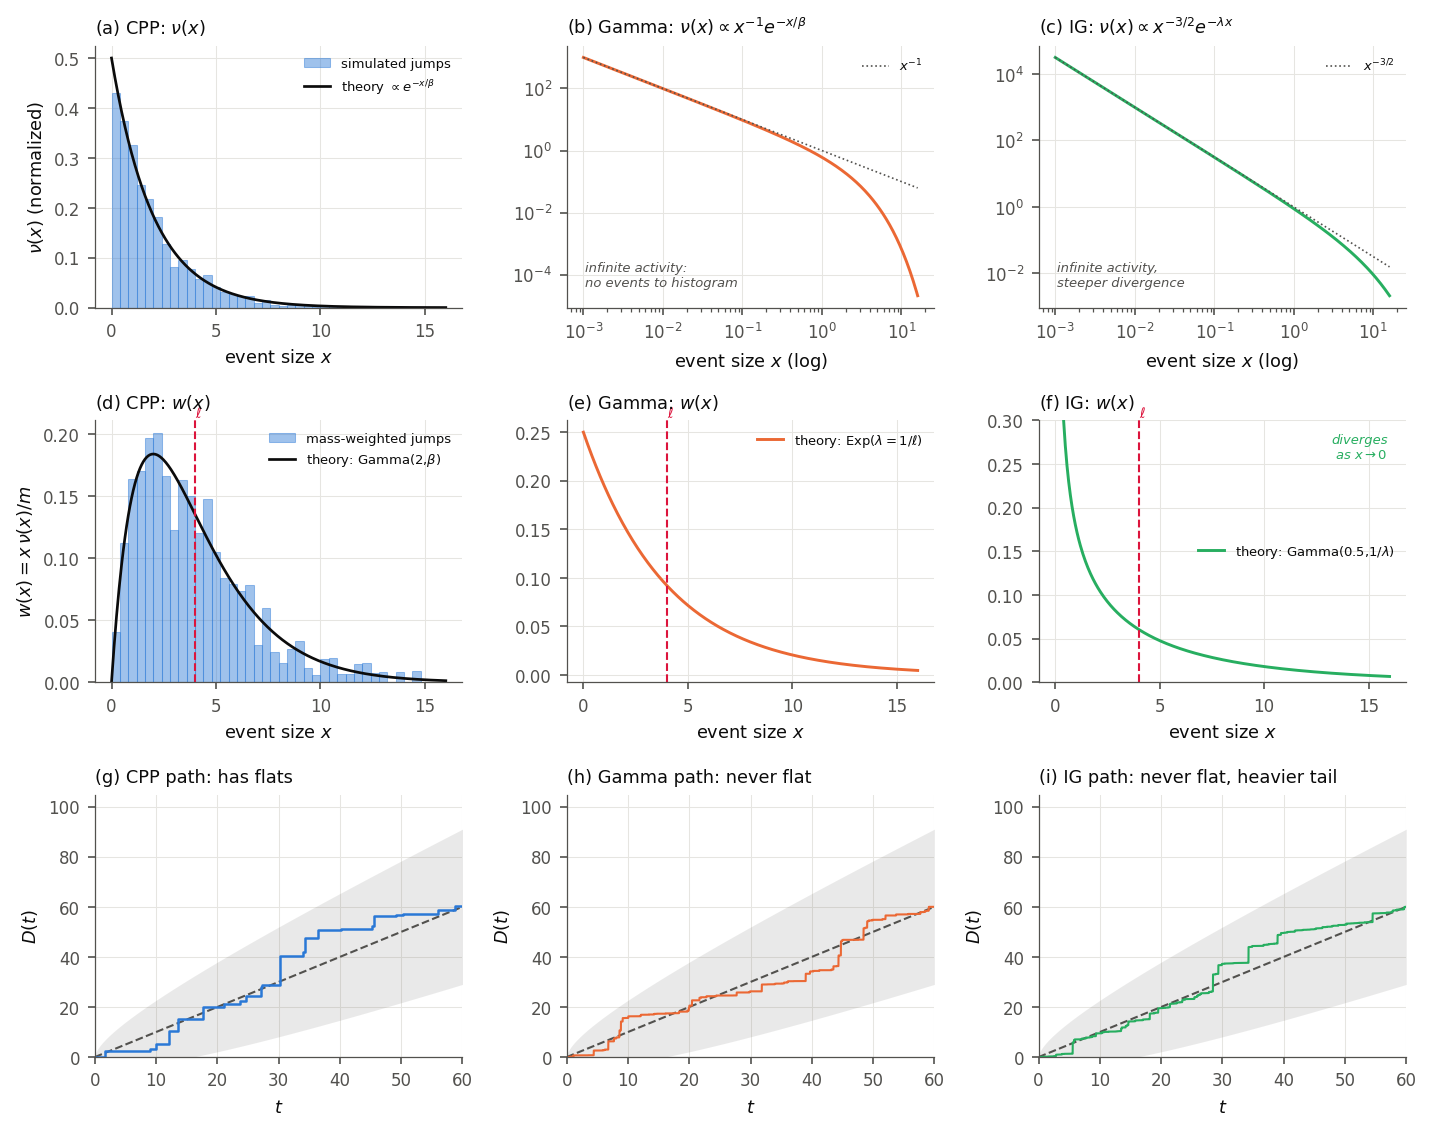

saved fig_event_spectrum_9panel.pdf/.png in notebooks/ (not a paper figure)


In [11]:
fig9, ax9 = plt.subplots(3, 3, figsize=(9.6, 7.6))
(aA, aB, aC), (aD, aE, aF), (aG, aH, aI) = ax9

# ---------------------------------------------------------------- row 1: nu(x)
aA.hist(jumps, bins=40, range=(0, 8 * beta), density=True,
        color=COL["CPP"], alpha=0.45, edgecolor=COL["CPP"], linewidth=0.5, label="simulated jumps")
aA.plot(xx, nu_pdf, color=INK, lw=1.3, label=r"theory $\propto e^{-x/\beta}$")
aA.set_ylabel(r"$\nu(x)$ (normalized)")
aA.set_title("(a) CPP: $\\nu(x)$", loc="left", fontsize=8.5)
aA.legend(fontsize=6.3)
aA.set_xlabel(r"event size $x$")

aB.loglog(xx_log, nu_gamma_log, color=COL["Gamma"], lw=1.4)
aB.loglog(xx_log, xx_log**-1 * np.exp(-xx_log[0] / beta), color=INK2, lw=0.8, ls=":", label=r"$x^{-1}$")
aB.set_title("(b) Gamma: $\\nu(x)\\propto x^{-1}e^{-x/\\beta}$", loc="left", fontsize=8.5)
aB.text(0.05, 0.08, "infinite activity:\nno events to histogram", fontsize=6.3, color=INK2,
        style="italic", transform=aB.transAxes)
aB.legend(fontsize=6.3)
aB.set_xlabel(r"event size $x$ (log)")

aC.loglog(xx_log, nu_ig_log, color=COL["IG"], lw=1.4)
aC.loglog(xx_log, xx_log**-1.5 * np.exp(-lam_ig * xx_log[0]), color=INK2, lw=0.8, ls=":", label=r"$x^{-3/2}$")
aC.set_title("(c) IG: $\\nu(x)\\propto x^{-3/2}e^{-\\lambda x}$", loc="left", fontsize=8.5)
aC.text(0.05, 0.08, "infinite activity,\nsteeper divergence", fontsize=6.3, color=INK2,
        style="italic", transform=aC.transAxes)
aC.legend(fontsize=6.3)
aC.set_xlabel(r"event size $x$ (log)")

# ---------------------------------------------------------------- row 2: w(x)
aD.hist(jumps, bins=40, range=(0, 8 * beta), density=True, weights=jumps / jumps.mean(),
        color=COL["CPP"], alpha=0.45, edgecolor=COL["CPP"], linewidth=0.5, label="mass-weighted jumps")
aD.plot(xx, w_pdf, color=INK, lw=1.3, label="theory: Gamma(2,$\\beta$)")
aD.axvline(ell, color="crimson", ls="--", lw=1.0)
aD.set_ylabel(r"$w(x)=x\,\nu(x)/m$")
aD.set_title("(d) CPP: $w(x)$", loc="left", fontsize=8.5)
aD.legend(fontsize=6.3)
aD.set_xlabel(r"event size $x$")

aE.plot(xx_g, w_gamma_pdf, color=COL["Gamma"], lw=1.4, label="theory: Exp($\\lambda{=}1/\\ell$)")
aE.axvline(ell, color="crimson", ls="--", lw=1.0)
aE.set_title("(e) Gamma: $w(x)$", loc="left", fontsize=8.5)
aE.legend(fontsize=6.3)
aE.set_xlabel(r"event size $x$")

aF.plot(xx_g, w_ig_pdf, color=COL["IG"], lw=1.4, label="theory: Gamma(0.5,$1/\\lambda$)")
aF.axvline(ell, color="crimson", ls="--", lw=1.0)
aF.set_ylim(0, 0.3)
aF.text(0.95, 0.95, "diverges\nas $x\\to0$", transform=aF.transAxes, fontsize=6.3,
        color=COL["IG"], ha="right", va="top", style="italic")
aF.set_title("(f) IG: $w(x)$", loc="left", fontsize=8.5)
aF.legend(fontsize=6.3, loc="center right")
aF.set_xlabel(r"event size $x$")

for ax in (aD, aE, aF):
    ax.text(ell, ax.get_ylim()[1], r"$\ell$", color="crimson", fontsize=6.5, ha="left", va="bottom")

# ---------------------------------------------------------------- row 3: sample paths, T=60
ylim9 = 1.15 * (mean_line6[-1] + band6[-1])
for ax, (t_, d_), col, label in zip(
    (aG, aH, aI),
    [(t_step6, y_step6), (t_gamma6, d_gamma6), (t_ig6, d_ig6)],
    (COL["CPP"], COL["Gamma"], COL["IG"]),
    ("(g) CPP path: has flats", "(h) Gamma path: never flat", "(i) IG path: never flat, heavier tail"),
):
    ax.fill_between(t_mean6, mean_line6 - band6, mean_line6 + band6, color=INK2, alpha=0.12, lw=0)
    ax.plot(t_mean6, mean_line6, color=INK2, ls="--", lw=1.0)
    if ax is aG:
        ax.step(np.concatenate((t_, [T_path6])), np.concatenate((d_, [d_[-1]])), where="post", color=col, lw=1.2)
    else:
        ax.plot(t_, d_, color=col, lw=1.0)
    ax.set_xlabel("$t$"); ax.set_ylabel("$D(t)$")
    ax.set_title(label, loc="left", fontsize=8.5)
    ax.set_xlim(0, T_path6)
    ax.set_ylim(0, ylim9)

fig9.tight_layout()
fig9.savefig("fig_event_spectrum_9panel.pdf", bbox_inches="tight")
fig9.savefig("fig_event_spectrum_9panel.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved fig_event_spectrum_9panel.pdf/.png in notebooks/ (not a paper figure)")

**Note on scope**: like the six-panel figure in §8, this nine-panel figure is exploratory material kept in this notebook; a clean copy (without this notebook's section numbering) is embedded as Figure 1 of `Manuscript/main.tex`.

## 10. Recovering the mechanism from skewness and kurtosis

This is the estimator-convergence style already used elsewhere in the
project (`fig3_skewness_convergence.pdf`, from
`stochastic_fouling_noiseless.ipynb`), extended from skewness alone to
skewness *and* kurtosis together, and framed around identification rather
than just validating the $\Delta^{-1/2}$/$\Delta^{-1}$ decay law.

The question this answers directly: *collect $N$ independent periods of
clean (noise-free) deposition data, compute the sample skewness and
kurtosis, and ask how quickly those estimates settle onto the true,
law-specific value as $N$ grows.* Unlike the noisy, aggregation-window
picture in the paper's Fig.~2(b) (`eq:attenuated_shape`, which shows why
realistic measurement noise makes this essentially hopeless for
realistic plant record lengths), this figure is the noise-free, "if only you had
enough clean samples" counterpart -- and the answer here is much more
encouraging: a few hundred to a few thousand independent periods is enough
for the bands to visibly separate, for both statistics. Read together, the
two figures make the paper's actual point: the obstacle to mechanism
recovery is not that skewness and kurtosis carry no information (they
clearly do, here), it is that realistic noise and realistic record lengths
destroy that information before it can be used.

In [12]:
import pandas as pd

g1_over_c = {"CPP": 1.5, "Gamma": 2.0, "IG": 3.0}
g2_over_c2 = {"CPP": 3.0, "Gamma": 6.0, "IG": 15.0}

# ---- single-period (window tau0) increment simulators, vectorized ----
def sim_cpp(n, rng):
    counts = rng.poisson(lam_rate * tau0, size=n)
    return rng.gamma(np.maximum(counts, 1), beta, size=n) * (counts > 0)

def sim_gamma(n, rng):
    return rng.gamma(tau0 / c**2, c**2 * m * tau0, size=n)

def sim_ig(n, rng):
    return rng.wald(m * tau0, m * tau0**2 / (c**2 * tau0), size=n)

SIM = {"CPP": sim_cpp, "Gamma": sim_gamma, "IG": sim_ig}
skew_theory = {law: g1_over_c[law] * c for law in g1_over_c}
kurt_theory = {law: g2_over_c2[law] * c**2 for law in g2_over_c2}
print("theory targets (bare, at c=2):")
for law in SIM:
    print(f"  {law}: skewness={skew_theory[law]}, excess kurtosis={kurt_theory[law]}")

theory targets (bare, at c=2):
  CPP: skewness=3.0, excess kurtosis=12.0
  Gamma: skewness=4.0, excess kurtosis=24.0
  IG: skewness=6.0, excess kurtosis=60.0


In [13]:
Ns = np.array([25, 50, 100, 250, 500, 1000, 2500, 5000, 10000, 25000, 50000, 100000])
n_trials = 300
rng = np.random.default_rng(1)

rows = []  # (law, N, stat, median, q05, q95)
for law, fun in SIM.items():
    for N in Ns:
        x = fun(n_trials * N, rng).reshape(n_trials, N)
        sk = stats.skew(x, axis=1, bias=False)
        ku = stats.kurtosis(x, axis=1, bias=False, fisher=True)
        rows.append((law, N, "skew", np.nanmedian(sk), np.nanquantile(sk, 0.05), np.nanquantile(sk, 0.95)))
        rows.append((law, N, "kurt", np.nanmedian(ku), np.nanquantile(ku, 0.05), np.nanquantile(ku, 0.95)))

conv = pd.DataFrame(rows, columns=["law", "N", "stat", "median", "q05", "q95"])
print(conv[(conv.stat == "skew") & (conv.N.isin([25, 1000, 10000, 25000, 50000, 100000]))].to_string(index=False))

  law      N stat   median      q05      q95
  CPP     25 skew 2.215256 1.235204 3.761642
  CPP   1000 skew 2.929367 2.509906 3.621964
  CPP  10000 skew 2.986296 2.837037 3.182477
  CPP  25000 skew 3.000505 2.893275 3.115788
  CPP  50000 skew 2.996119 2.927238 3.085491
  CPP 100000 skew 3.000820 2.944732 3.062324
Gamma     25 skew 2.471831 1.246512 3.965499
Gamma   1000 skew 3.758960 3.040942 4.959257
Gamma  10000 skew 3.960353 3.641068 4.448722
Gamma  25000 skew 3.980809 3.764082 4.278599
Gamma  50000 skew 3.985390 3.810592 4.198763
Gamma 100000 skew 3.993927 3.884765 4.134729
   IG     25 skew 2.639731 1.402569 4.489670
   IG   1000 skew 5.165333 4.001412 7.678038
   IG  10000 skew 5.821625 5.095202 7.202163
   IG  25000 skew 5.961192 5.437502 6.795377
   IG  50000 skew 5.941826 5.554382 6.556291
   IG 100000 skew 5.959432 5.636764 6.466473


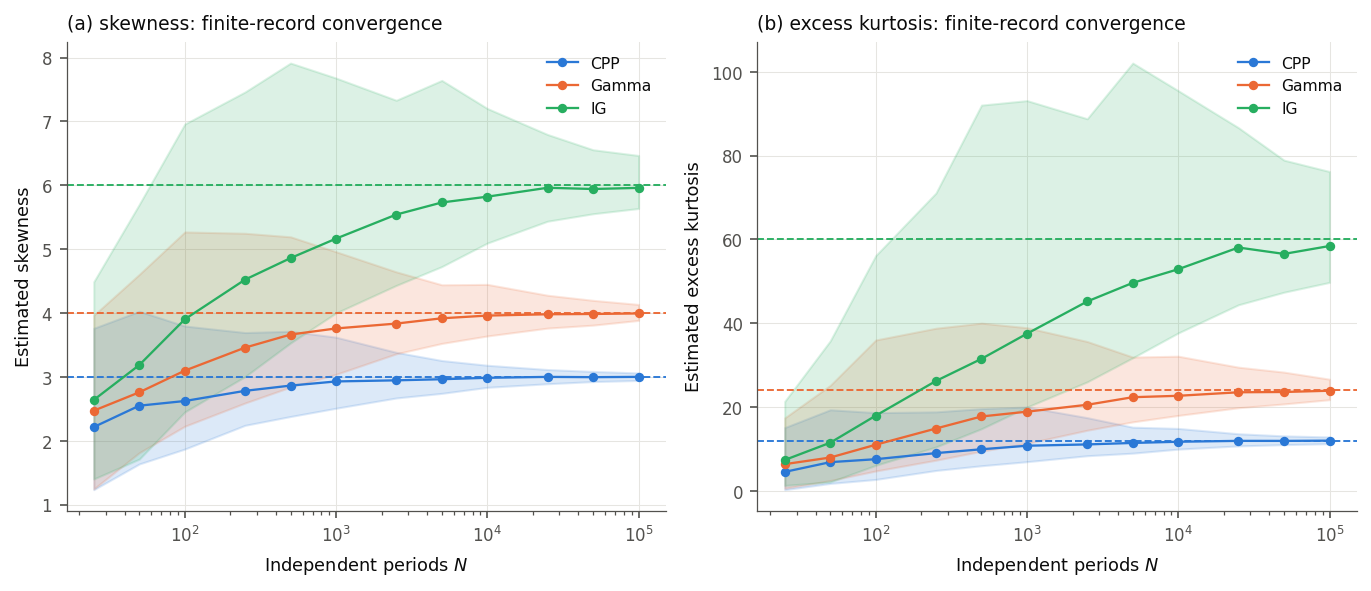

saved fig_mechanism_recovery.pdf/.png in notebooks/


In [14]:
fig11, (axS, axK) = plt.subplots(1, 2, figsize=(9.2, 4.0))

for law in SIM:
    d = conv[(conv.law == law) & (conv.stat == "skew")]
    axS.plot(d.N, d["median"], "o-", ms=3.5, color=COL[law], label=law)
    axS.fill_between(d.N.to_numpy(), d.q05.to_numpy(), d.q95.to_numpy(), color=COL[law], alpha=0.16)
    axS.axhline(skew_theory[law], color=COL[law], ls="--", lw=0.9)
axS.set_xscale("log")
axS.set_xlabel(r"Independent periods $N$")
axS.set_ylabel("Estimated skewness")
axS.set_title("(a) skewness: finite-record convergence", loc="left", fontsize=9)
axS.legend(fontsize=7.5)

for law in SIM:
    d = conv[(conv.law == law) & (conv.stat == "kurt")]
    axK.plot(d.N, d["median"], "o-", ms=3.5, color=COL[law], label=law)
    axK.fill_between(d.N.to_numpy(), d.q05.to_numpy(), d.q95.to_numpy(), color=COL[law], alpha=0.16)
    axK.axhline(kurt_theory[law], color=COL[law], ls="--", lw=0.9)
axK.set_xscale("log")
axK.set_xlabel(r"Independent periods $N$")
axK.set_ylabel("Estimated excess kurtosis")
axK.set_title("(b) excess kurtosis: finite-record convergence", loc="left", fontsize=9)
axK.legend(fontsize=7.5)

fig11.tight_layout()
fig11.savefig("fig_mechanism_recovery.pdf", bbox_inches="tight")
fig11.savefig("fig_mechanism_recovery.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved fig_mechanism_recovery.pdf/.png in notebooks/")

**Reading the figure**: both panels converge cleanly onto the correct,
law-specific theoretical value (dashed lines, the Table~tab:three_laws
values at $c=2$) as $N$ grows -- unlike the noisy version, the bands here
*do* separate, for both statistics, well within a feasible record length
($N\sim10^2$--$10^3$). This is the figure's point: skewness and kurtosis
genuinely do identify the mechanism, given enough *clean* samples. What
makes identification hard in practice is not a fundamental information
problem -- it is realistic measurement noise, which (paper Fig.~2(b),
`eq:attenuated_shape`) attenuates the very same statistics far below what a
feasible record length can resolve in practice.

## 11. Aggregation and approach to Gaussian behavior (Sec. II.D)

This builds the figure for Sec.~II.D (`sec:aggregation`), illustrating the
central-limit-theorem content of Eq. `eq:aggregation_scaling` directly: as
the observation window $\Delta$ grows past the crossover $\Delta_c$
(Eq. `eq:crossover_window`), the standardized skewness and excess kurtosis
of all three laws decay to zero -- with the *same* power-law exponent
across laws ($\Delta^{-1/2}$ and $\Delta^{-1}$ respectively), only the
prefactor and hence $\Delta_c$ differing -- and the increment distribution
itself visibly approaches the Gaussian.

Four panels, all closed-form (no Monte Carlo needed):
(a) skewness $\gamma_1(\Delta)$ vs. $\Delta/\tau_0$, log-log, slope $-1/2$,
crossover $\Delta_c$ ($\gamma_1=1$) marked for each law;
(b) excess kurtosis $\gamma_2(\Delta)$ vs. $\Delta/\tau_0$, log-log, slope
$-1$, crossover $\Delta_c'$ ($\gamma_2=1$) marked;
(c) standardized increment density at $\Delta=\tau_0$, still visibly
non-Gaussian (CPP shows the point mass at zero from genuine quiescence);
(d) the same at $\Delta=10\tau_0$, nearly indistinguishable from
$\mathcal N(0,1)$. Panels (c)-(d) use the same $m,c,\tau_0$ as the rest of
this notebook ($c=2$), so the point-mass probability at $\Delta=\tau_0$
($e^{-2\Delta/t_c}\approx0.61$) is a real, visible feature.

In [15]:
from scipy.special import gammaln

# ---------------------------------------------------------------- (a)-(b): decay of skewness/kurtosis
g1_over_c_agg = {"CPP": 1.5, "Gamma": 2.0, "IG": 3.0}
g2_over_c2_agg = {"CPP": 3.0, "Gamma": 6.0, "IG": 15.0}
ALPHA = {"CPP": -1.0, "Gamma": 0.0, "IG": 0.5}
LS = {"CPP": "-", "Gamma": "--", "IG": ":"}

def crossover_over_tau0(alpha):
    return ((2 - alpha) / (1 - alpha)) ** 2  # Delta_c/tau0 where gamma_1=1 at c=1... rescaled below

Delta_over_tau0 = np.logspace(-1, 2.7, 300)

# ---------------------------------------------------------------- (c)-(d): standardized increment density
def cpp_density(x, Delta, beta_, n_max=400):
    """Exact CPP density for x>0; point mass at 0 handled separately."""
    r = 2.0 / t_c
    lam = r * Delta
    n = np.arange(1, n_max + 1)
    logw = n * np.log(lam) - lam - gammaln(n + 1)
    w = np.exp(logw)
    w = w / w.sum() * (1 - np.exp(-lam))
    dens = np.zeros_like(x)
    for ni, wi in zip(n, w):
        dens += wi * stats.gamma.pdf(x, a=ni, scale=beta_)
    p0 = np.exp(-lam)
    return dens, p0

def standardized_panel(Delta, ax, show_gaussian=False, show_legend=False):
    sigma = c * m * np.sqrt(tau0 * Delta)
    zz = np.linspace(-3, 6, 900)
    xx_ = m * Delta + sigma * zz

    dens_cpp, p0 = cpp_density(np.maximum(xx_, 1e-12), Delta, beta)
    dens_cpp = np.where(xx_ > 0, dens_cpp, 0.0)
    dens_z_cpp = dens_cpp * sigma
    z0 = (0 - m * Delta) / sigma

    shape_g = Delta / (c**2 * tau0)
    scale_g = c**2 * m * tau0
    dens_z_gamma = stats.gamma.pdf(xx_, a=shape_g, scale=scale_g) * sigma

    mu_ig = m * Delta
    lam_ig_ = m * Delta**2 / (c**2 * tau0)
    mu_s = mu_ig / lam_ig_
    dens_z_ig = stats.invgauss.pdf(xx_, mu=mu_s, scale=lam_ig_) * sigma

    ax.plot(zz, dens_z_gamma, color=COL["Gamma"], ls=LS["Gamma"], label="Gamma")
    ax.plot(zz, dens_z_ig, color=COL["IG"], ls=LS["IG"], label="Inverse Gaussian")
    ax.plot(zz, dens_z_cpp, color=COL["CPP"], ls=LS["CPP"], label="Compound Poisson")
    ax.scatter([z0], [p0], color=COL["CPP"], marker="o", s=20, zorder=5)
    ax.vlines([z0], 0, p0, color=COL["CPP"], lw=1.0)
    if show_gaussian:
        ax.plot(zz, stats.norm.pdf(zz), color=INK, lw=1.4, alpha=0.9, label=r"$\mathcal{N}(0,1)$")
    ax.set_xlabel("Standardized increment $Z$")
    ax.set_xlim(-3, 6)
    if show_legend:
        ax.legend(fontsize=6.8, loc="upper right")

print("t_c =", t_c, " p0 at Delta=tau0:", np.exp(-2 * tau0 / t_c), " at Delta=10 tau0:", np.exp(-2 * 10 * tau0 / t_c))


t_c = 4.0  p0 at Delta=tau0: 0.6065306597126334  at Delta=10 tau0: 0.006737946999085467


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


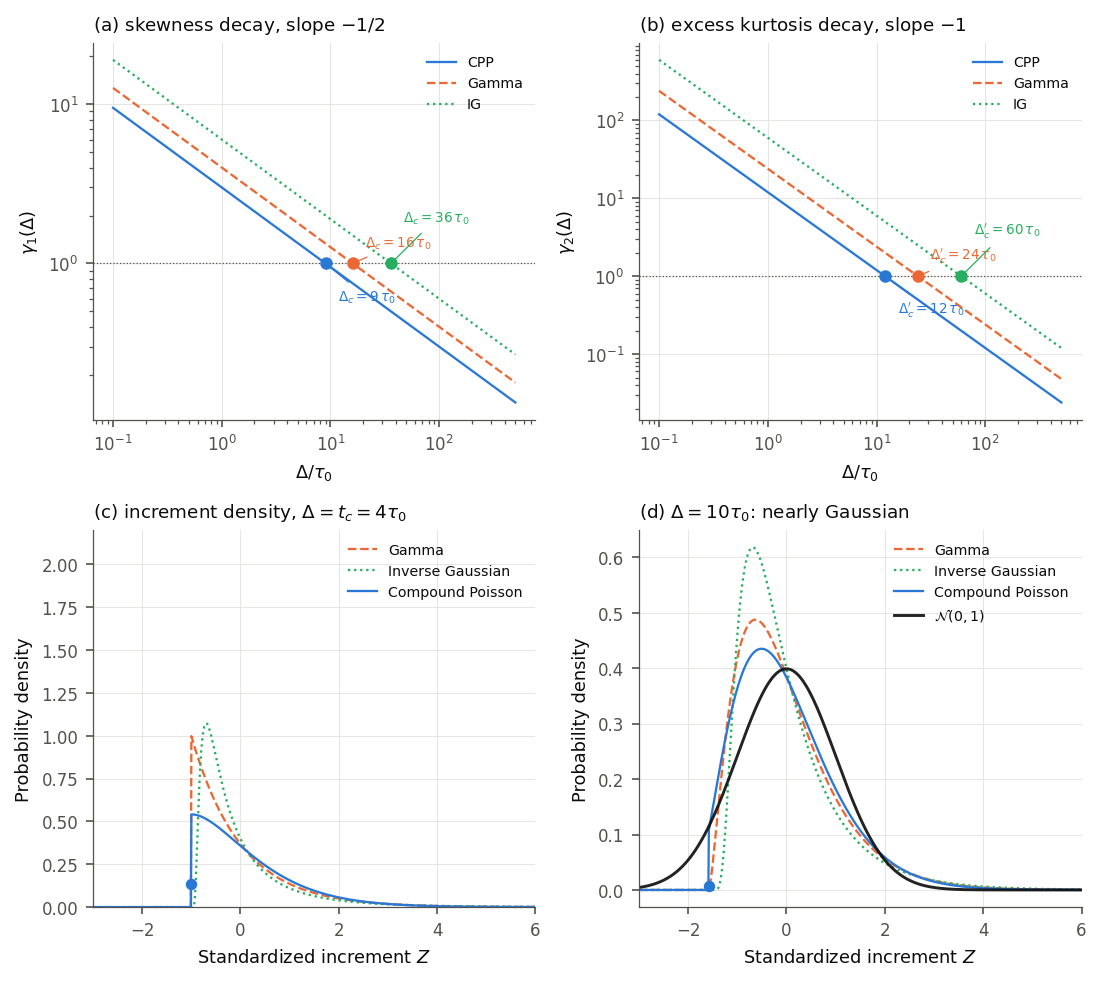

saved fig_aggregation_clt.pdf


In [16]:
fig12, axes12 = plt.subplots(2, 2, figsize=(7.4, 6.6))
axA, axB = axes12[0]
axC, axD = axes12[1]

# (a) skewness decay
y_offsets_s = {"CPP": -18, "Gamma": 8, "IG": 20}
for law in ("CPP", "Gamma", "IG"):
    gamma1 = g1_over_c_agg[law] * c * np.sqrt(tau0 / (Delta_over_tau0 * tau0))
    axA.loglog(Delta_over_tau0, gamma1, color=COL[law], ls=LS[law], label=law)
    Dc = c**2 * crossover_over_tau0(ALPHA[law])  # gamma1=1 => (g1/c * c)*sqrt(1/(D/tau0))=1 => D/tau0=(g1_over_c*c)^2
    axA.plot(Dc, 1.0, "o", color=COL[law], ms=5, zorder=5)
    axA.annotate(rf"$\Delta_c={Dc:.3g}\,\tau_0$", xy=(Dc, 1.0), xytext=(6, y_offsets_s[law]),
                 textcoords="offset points", fontsize=6.5, color=COL[law],
                 arrowprops=dict(arrowstyle="-", color=COL[law], lw=0.6))
axA.axhline(1.0, color=INK2, lw=0.6, ls=":")
axA.set_xlabel(r"$\Delta/\tau_0$")
axA.set_ylabel(r"$\gamma_1(\Delta)$")
axA.set_title(r"(a) skewness decay, slope $-1/2$", loc="left", fontsize=8.8)
axA.legend(fontsize=6.8)

# (b) kurtosis decay
y_offsets_k = {"CPP": -18, "Gamma": 8, "IG": 20}
for law in ("CPP", "Gamma", "IG"):
    gamma2 = g2_over_c2_agg[law] * c**2 * (tau0 / (Delta_over_tau0 * tau0))
    axB.loglog(Delta_over_tau0, gamma2, color=COL[law], ls=LS[law], label=law)
    Dcp = g2_over_c2_agg[law] * c**2
    axB.plot(Dcp, 1.0, "o", color=COL[law], ms=5, zorder=5)
    axB.annotate(rf"$\Delta_c'={Dcp:.3g}\,\tau_0$", xy=(Dcp, 1.0), xytext=(6, y_offsets_k[law]),
                 textcoords="offset points", fontsize=6.5, color=COL[law],
                 arrowprops=dict(arrowstyle="-", color=COL[law], lw=0.6))
axB.axhline(1.0, color=INK2, lw=0.6, ls=":")
axB.set_xlabel(r"$\Delta/\tau_0$")
axB.set_ylabel(r"$\gamma_2(\Delta)$")
axB.set_title(r"(b) excess kurtosis decay, slope $-1$", loc="left", fontsize=8.8)
axB.legend(fontsize=6.8)

# (c) Delta = tau0
standardized_panel(4 * tau0, axC, show_gaussian=False, show_legend=True)
axC.set_ylabel("Probability density")
axC.set_title(r"(c) increment density, $\Delta=t_c=4\tau_0$", loc="left", fontsize=8.8)
axC.set_ylim(0, 2.2)

# (d) Delta = 10 tau0
standardized_panel(10 * tau0, axD, show_gaussian=True, show_legend=True)
axD.set_ylabel("Probability density")
axD.set_title(r"(d) $\Delta=10\tau_0$: nearly Gaussian", loc="left", fontsize=8.8)

fig12.tight_layout()
fig12.savefig(OUT_DIR / "fig_aggregation_clt.pdf", bbox_inches="tight")
fig12.savefig(OUT_DIR / "fig_aggregation_clt.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved fig_aggregation_clt.pdf")


**Reading the figure**: (a)-(b) make the point of Eq. `eq:aggregation_scaling`
visually -- all three laws decay with the same exponent, differing only in
prefactor and hence in how long the crossover takes; the inverse Gaussian,
with the broadest event-size spectrum, needs the longest window before its
higher cumulants become negligible. (c)-(d) show what that decay means for
the distribution itself: at $\Delta=\tau_0$ the laws are still visibly
distinct (in particular CPP's genuine point mass at $Z=0$, absent for the
infinite-activity laws), while at $\Delta=10\tau_0$ all three, including
CPP, are close to indistinguishable from the Gaussian -- illustrating the
central limit theorem of Remark 2 directly.